In [1]:
import pandas as pd
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split


In [2]:
data=pd.read_csv(r"D:\HOPEAI\ML Resources\Machine Learning-Classification\Week4.0-Machine Learning-Classification\CLassification\1.Traditional Way\Social_Network_Ads.csv")

In [3]:
data.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [4]:
data["Purchased"].value_counts()

Purchased
0    257
1    143
Name: count, dtype: int64

In [5]:
data=pd.get_dummies(data,columns=["Gender"],drop_first=True,dtype=int)

In [6]:
data.head()

,User ID,Age,EstimatedSalary,Purchased,Gender_Male
0,15624510,19,19000,0,1
1,15810944,35,20000,0,1
2,15668575,26,43000,0,0
3,15603246,27,57000,0,0
4,15804002,19,76000,0,1


In [7]:
X=data.drop(columns=["Purchased","User ID"],axis=1)

In [8]:
y=data["Purchased"]

In [9]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42)

In [10]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
X_train=sc.fit_transform(X_train)
X_test=sc.transform(X_test)

In [11]:
svc_grid=SVC()
svc_grid.fit(X_train,y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [19]:
from sklearn.model_selection import GridSearchCV

param_grid={"kernel":["linear", "poly", "rbf", "sigmoid"],"gamma":["scale","auto"],"C":[10,100,1000,2000,3000]}
grid=GridSearchCV(SVC(probability=True),param_grid,refit=True,verbose=3,n_jobs=-1,cv=5,scoring="f1_weighted")
grid.fit(X_train,y_train)

Fitting 5 folds for each of 40 candidates, totalling 200 fits


,estimator,SVC(probability=True)
,param_grid,"{'C': [10, 100, ...], 'gamma': ['scale', 'auto'], 'kernel': ['linear', 'poly', ...]}"
,scoring,'f1_weighted'
,n_jobs,-1
,refit,True
,cv,5
,verbose,3
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,C,10


In [23]:
y_pred=grid.predict(X_test)
y_pred

array([1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0,
       1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1,
       0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1,
       0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1,
       0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0,
       0, 0, 1, 1, 1, 0, 0, 0, 0, 0], dtype=int64)

In [24]:
from sklearn.metrics import classification_report,confusion_matrix

report=classification_report(y_test,y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.96      0.93      0.94        73
           1       0.90      0.94      0.92        47

    accuracy                           0.93       120
   macro avg       0.93      0.93      0.93       120
weighted avg       0.93      0.93      0.93       120



In [25]:
cm=confusion_matrix(y_test,y_pred)

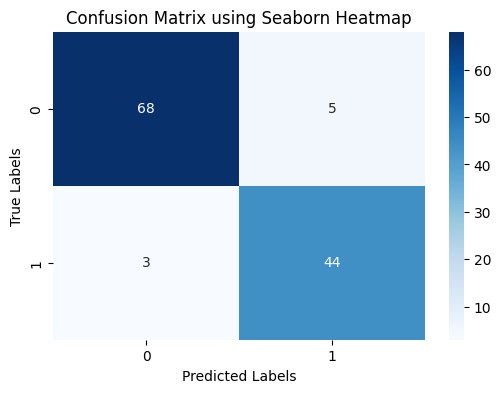

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,4))
sns.heatmap(cm, 
    annot=True,            # Show the numbers inside the blocks
    fmt='d',               # Print numbers as integers 
    cmap='Blues',   )       # Colormap style
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix using Seaborn Heatmap')
plt.show()


In [27]:
y_prob=grid.predict_proba(X_test)[:,1]
y_prob

array([0.88130983, 0.80035123, 0.00325147, 0.70318002, 0.00540602,
       0.00589353, 0.77650949, 0.06680416, 0.1637396 , 0.08846971,
       0.01323373, 0.95089274, 0.00803632, 0.03565545, 0.15826373,
       0.90479945, 0.93952526, 0.40959848, 0.05735493, 0.86677172,
       0.0169955 , 0.0548672 , 0.93326729, 0.78359399, 0.05994316,
       0.97419391, 0.36157425, 0.02054884, 0.8397904 , 0.05158946,
       0.71041328, 0.01705659, 0.88658235, 0.04048785, 0.94234713,
       0.07757707, 0.02084684, 0.03002982, 0.01277069, 0.05177399,
       0.81797839, 0.00747982, 0.01791618, 0.95452357, 0.01210238,
       0.82831696, 0.00801723, 0.01484598, 0.60387714, 0.00598694,
       0.02699866, 0.76673419, 0.02257584, 0.03000271, 0.08564147,
       0.00511905, 0.98069763, 0.72543654, 0.03561663, 0.04628311,
       0.09125877, 0.00839745, 0.76317032, 0.1106119 , 0.00676341,
       0.81095535, 0.40294407, 0.81212093, 0.03537064, 0.78715857,
       0.82620529, 0.03977866, 0.00626504, 0.03094235, 0.73562

In [28]:
from sklearn.metrics import roc_auc_score
roc_auc_score(y_test,y_prob)

0.9711454386476246

In [31]:
grid.cv_results_

pd.DataFrame.from_dict(grid.cv_results_)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_C,param_gamma,param_kernel,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.033262,0.004662,0.017540,0.005022,10,scale,linear,"{'C': 10, 'gamma': 'scale', 'kernel': 'linear'}",0.789882,0.872078,0.806330,0.769243,0.791441,0.805795,0.035182,21
1,0.038040,0.005623,0.013437,0.005588,10,scale,poly,"{'C': 10, 'gamma': 'scale', 'kernel': 'poly'}",0.828085,0.910103,0.794907,0.824830,0.731250,0.817835,0.057776,19
2,0.020225,0.006818,0.018550,0.006835,10,scale,rbf,"{'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}",0.912095,0.872078,0.928571,0.842807,0.911174,0.893345,0.031358,1
3,0.024665,0.007129,0.019192,0.006341,10,scale,sigmoid,"{'C': 10, 'gamma': 'scale', 'kernel': 'sigmoid'}",0.719728,0.714286,0.658391,0.660491,0.823129,0.715205,0.059817,36
4,0.041317,0.007849,0.022463,0.007855,10,auto,linear,"{'C': 10, 'gamma': 'auto', 'kernel': 'linear'}",0.789882,0.872078,0.806330,0.769243,0.791441,0.805795,0.035182,21
5,0.043744,0.010329,0.021001,0.006953,10,auto,poly,"{'C': 10, 'gamma': 'auto', 'kernel': 'poly'}",0.828085,0.910103,0.794907,0.824830,0.731250,0.817835,0.057776,19
6,0.035727,0.005360,0.019167,0.007028,10,auto,rbf,"{'C': 10, 'gamma': 'auto', 'kernel': 'rbf'}",0.912095,0.872078,0.928571,0.842807,0.911174,0.893345,0.031358,1
7,0.031623,0.001307,0.019156,0.005133,10,auto,sigmoid,"{'C': 10, 'gamma': 'auto', 'kernel': 'sigmoid'}",0.719728,0.714286,0.658391,0.660491,0.823129,0.715205,0.059817,36
8,0.165216,0.037982,0.023998,0.007810,100,scale,linear,"{'C': 100, 'gamma': 'scale', 'kernel': 'linear'}",0.789882,0.872078,0.806330,0.769243,0.791441,0.805795,0.035182,21
9,0.239700,0.098167,0.019343,0.004209,100,scale,poly,"{'C': 100, 'gamma': 'scale', 'kernel': 'poly'}",0.828085,0.928571,0.815503,0.842807,0.731250,0.829243,0.062997,11


In [32]:
grid.classes_

array([0, 1], dtype=int64)

In [33]:
from sklearn.metrics import roc_auc_score
roc_auc_score(y_test,y_prob)

0.9711454386476246